In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


diffus = pd.read_csv('L_diffus_eq.txt', sep=r'\s+', names=['time', 'value'])
low = pd.read_csv('L_low_bc.txt', sep=r'\s+', names=['time', 'value'])
ln = pd.read_csv('L_n.txt', sep=r'\s+', names=['time', 'value'])
lx = pd.read_csv('L_xmom_eq.txt', sep=r'\s+', names=['time', 'value'])
ly = pd.read_csv('L_ymom_eq.txt', sep=r'\s+', names=['time', 'value'])
df = diffus[['time']].copy()
df['L_diffus'] = diffus['value'].values
df['L_low'] = low['value'].values
df['L_n'] = ln['value'].values
df['L_x'] = lx['value'].values
df['L_y'] = ly['value'].values

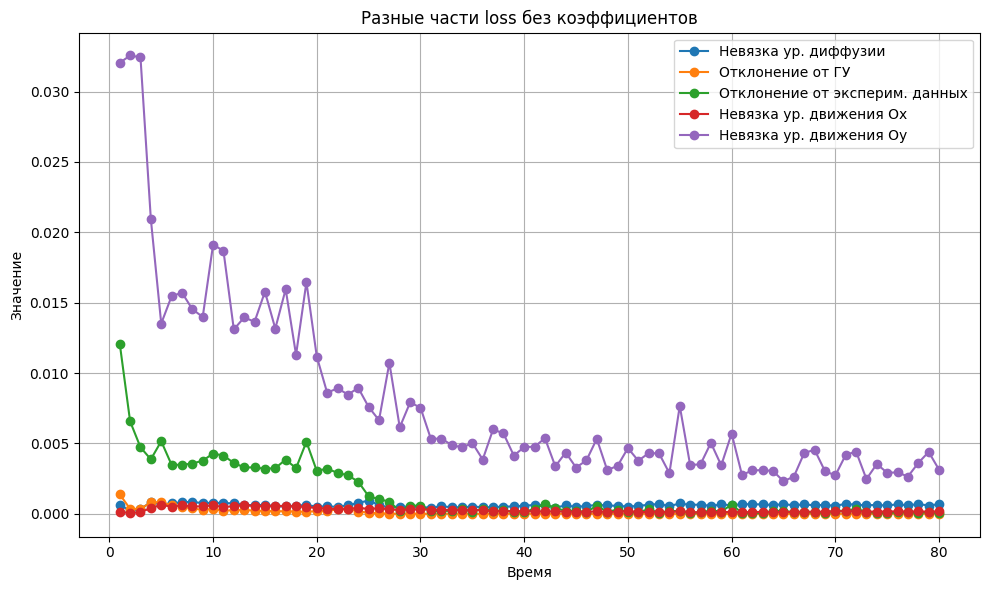

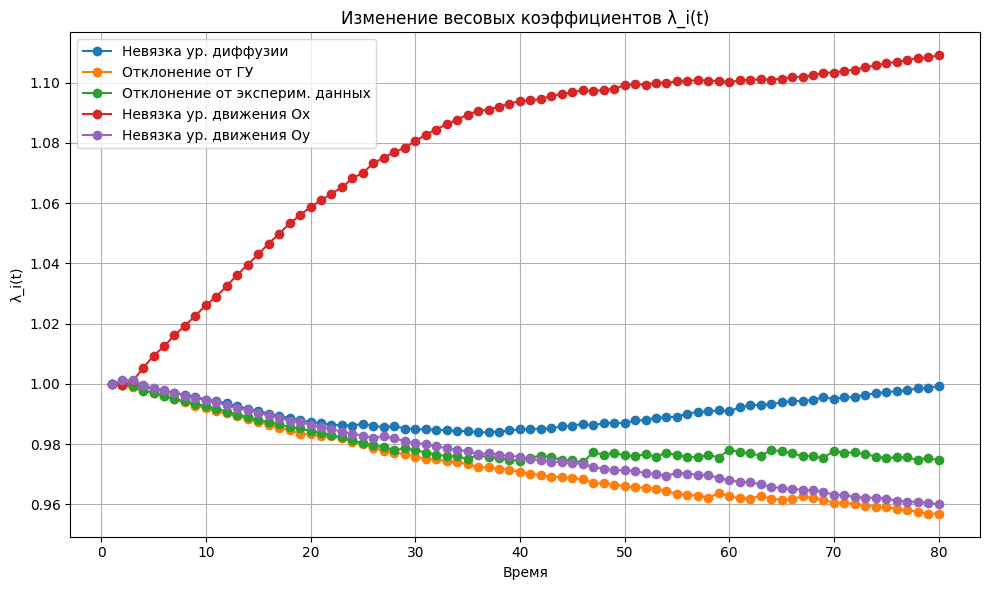

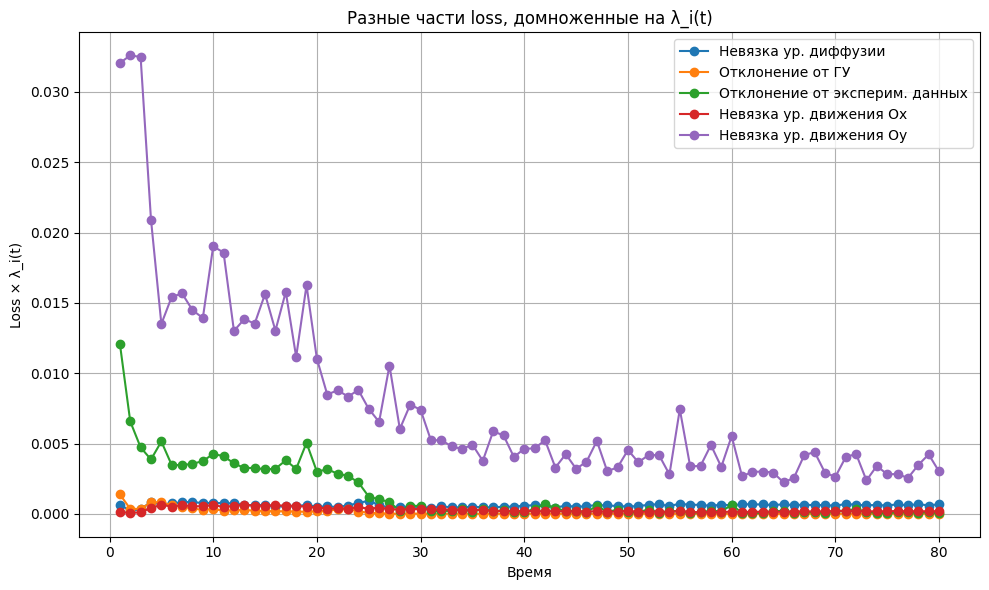

In [3]:
loss_names = [
    'Невязка ур. диффузии',
    'Отклонение от ГУ',
    'Отклонение от эксперим. данных',
    'Невязка ур. движения Ox',
    'Невязка ур. движения Oy',
]
losses = df[['L_diffus', 'L_low', 'L_n', 'L_x', 'L_y']].values.astype(float)
times = df['time'].values
m = losses.shape[1]

eps = 1e-12
losses_safe = np.where(losses > 0, losses, eps)

def softmax(z):
    e = np.exp(z - np.max(z))
    return e / e.sum()

T = 1.0
rho = 0.999
alpha = 0.999

n = len(losses_safe)
lam_bal_0 = np.zeros((n, m))
lam_bal_prev = np.zeros((n, m))

for t in range(n):
    lam_bal_0[t] = m * softmax(losses_safe[t] / (T * losses_safe[0]))
    if t == 0:
        lam_bal_prev[t] = m * softmax(losses_safe[0] / (T * losses_safe[0]))
    else:
        lam_bal_prev[t] = m * softmax(losses_safe[t] / (T * losses_safe[t - 1]))

lam = np.ones((n, m))
lam_hist = np.ones((n, m))

for t in range(1, n):
    lam_hist[t] = rho * lam[t - 1] + (1 - rho) * lam_bal_0[t]
    lam[t] = alpha * lam_hist[t] + (1 - alpha) * lam_bal_prev[t]

fig, ax = plt.subplots(figsize=(10, 6))
for i in range(m):
    ax.plot(times, losses[:, i], marker='o', label=loss_names[i])
ax.set_title('Разные части loss без коэффициентов')
ax.set_xlabel('Время')
ax.set_ylabel('Значение')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for i in range(m):
    ax.plot(times, lam[:, i], marker='o', label=loss_names[i])
ax.set_title('Изменение весовых коэффициентов λ_i(t)')
ax.set_xlabel('Время')
ax.set_ylabel('λ_i(t)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(10, 6))
for i in range(m):
    ax.plot(times, losses[:, i] * lam[:, i], marker='o', label=loss_names[i])
ax.set_title('Разные части loss, домноженные на λ_i(t)')
ax.set_xlabel('Время')
ax.set_ylabel('Loss × λ_i(t)')
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()